In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *



In [2]:
#domainM='GRq'; nx=ny=10
#domainM='GRq'
#ds_TTZ_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRq/spin2/work/daily/'+
#    'TTZ_daymean_MARv3.14_ER5_spin2_GRq_*.nc')['TTZ'].sel(ZTQLEV=2)
#ds_TTZ= ds_TTZ_raw.rename({'TIME': 'time'})
#ds_TTZ=ds_TTZ[:,ny:-ny,nx:-nx]

In [3]:
plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

In [4]:
resultsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/compu_results/'

In [5]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/nat_geo_stations_everest/'
#sourceData='/Users/santolam/Desktop/nat_geo_stations_everest/'
##
file_bc='Base_Camp_20230630.csv'
file_c2='Camp2_20230630.csv'
file_phort='Phortse_20230630.csv'
file_bish='Bishop_Rock_20230630.csv'
file_sc='South_Col_20230630.csv'

df_bc = pd.read_csv(os.path.join(sourceData, file_bc), parse_dates=['TIMESTAMP'])
df_c2 = pd.read_csv(os.path.join(sourceData, file_c2), parse_dates=['TIMESTAMP'])
df_phort = pd.read_csv(os.path.join(sourceData, file_phort), parse_dates=['TIMESTAMP'])
df_bish = pd.read_csv(os.path.join(sourceData, file_bish), parse_dates=['TIMESTAMP'])
df_sc = pd.read_csv(os.path.join(sourceData, file_sc), parse_dates=['TIMESTAMP'])

# Optional: set timestamp as index
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    #print(df.head())
    df.set_index('TIMESTAMP', inplace=True)

# Quick check
print(df_bc.head())
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    df[df < -100] = np.nan
    
tt_bc_daily = df_bc['T_HMP'].resample('D').mean()
tt_c2_daily = df_c2['T_HMP'].resample('D').mean()
tt_phort_daily = df_phort['T_HMP'].resample('D').mean()
tt_bish_daily = df_bish['T_HMP'].resample('D').mean()
tt_sc_daily = df_sc['T_HMP'].resample('D').mean()


                     T_HMP      RH   PRESS  PRECIP
TIMESTAMP                                         
2019-10-17 13:00:00 -4.078  99.578  536.71     0.0
2019-10-17 14:00:00 -4.282  92.273  537.15     0.0
2019-10-17 15:00:00 -3.584  86.358  537.28     0.0
2019-10-17 16:00:00 -3.458  88.629  537.25     0.0
2019-10-17 17:00:00 -3.966  74.045  537.22     0.0


In [6]:
lat_bc, lon_bc, elev_bc = 27.9952, 86.8406, 5315

# CAMP II AWS (27.9810 N, 86.9023 E, 6464 M ASL)
lat_c2, lon_c2, elev_c2 = 27.9810, 86.9023, 6464 

# PHORTSE AWS (27.8456 N, 86.7472 E, 3810 M ASL)
lat_phort, lon_phort, elev_phort = 27.8456, 86.7472, 3810 

# BISHOP ROCK AWS (27.9735 N, 86.9308 E, 8810 M ASL)
lat_bish, lon_bish, elev_bish = 27.9735, 86.9308, 8810 

# MT. EVEREST SOUTH COL AWS (27.9719 N, 86.9295 E, 7945 M ASL)
lat_sc, lon_sc, elev_sc = 27.9719, 86.9295, 7945


# Define metadata for Everest AWS network using variables
stations_info_everest = [
    {"ID": "BC", "Name": "Base Camp AWS", "Lat": lat_bc, "Lon": lon_bc, "Elev_m": elev_bc},
    {"ID": "C2", "Name": "Camp II AWS", "Lat": lat_c2, "Lon": lon_c2, "Elev_m": elev_c2},
    {"ID": "PHO", "Name": "Phortse AWS", "Lat": lat_phort, "Lon": lon_phort, "Elev_m": elev_phort},
    {"ID": "BIS", "Name": "Bishop Rock AWS", "Lat": lat_bish, "Lon": lon_bish, "Elev_m": elev_bish},
    {"ID": "SC", "Name": "Mt. Everest South Col AWS", "Lat": lat_sc, "Lon": lon_sc, "Elev_m": elev_sc},
]

# Create DataFrame
df_everest_stations = pd.DataFrame(stations_info_everest)

# Display
print(df_everest_stations)


    ID                       Name      Lat      Lon  Elev_m
0   BC              Base Camp AWS  27.9952  86.8406    5315
1   C2                Camp II AWS  27.9810  86.9023    6464
2  PHO                Phortse AWS  27.8456  86.7472    3810
3  BIS            Bishop Rock AWS  27.9735  86.9308    8810
4   SC  Mt. Everest South Col AWS  27.9719  86.9295    7945


In [7]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}
# Add NatGeo / Everest AWS
for sta in stations_info_everest:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "NatGeo")

# Check summary
print(f"Total stations merged: {len(stations_all)}")
print(stations_all.keys())

Total stations merged: 5
dict_keys(['BC', 'C2', 'PHO', 'BIS', 'SC'])


In [8]:
idate_bc = str(tt_bc_daily.index[0].date())
fdate_bc = str(tt_bc_daily.index[-1].date())

idate_c2 = str(tt_c2_daily.index[0].date())
fdate_c2 = str(tt_c2_daily.index[-1].date())

idate_phort = str(tt_phort_daily.index[0].date())
fdate_phort = str(tt_phort_daily.index[-1].date())

idate_bish = str(tt_bish_daily.index[0].date())
fdate_bish = str(tt_bish_daily.index[-1].date())

idate_sc = str(tt_sc_daily.index[0].date())
fdate_sc = str(tt_sc_daily.index[-1].date())


In [9]:
# --- Observed daily mean temperature (°C) ---
stations_tt_daily_natgeo = {
    "BaseCamp": tt_bc_daily,
    "Camp2": tt_c2_daily,
    "Phortse": tt_phort_daily,
    "BishopRock": tt_bish_daily,
    "SouthCol": tt_sc_daily,
}

In [ ]:
###Coordinates

In [14]:
#stations_tt_daily_natgeo

 Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/support_FIGSX_timeseries_daily_tas.natgeo.png


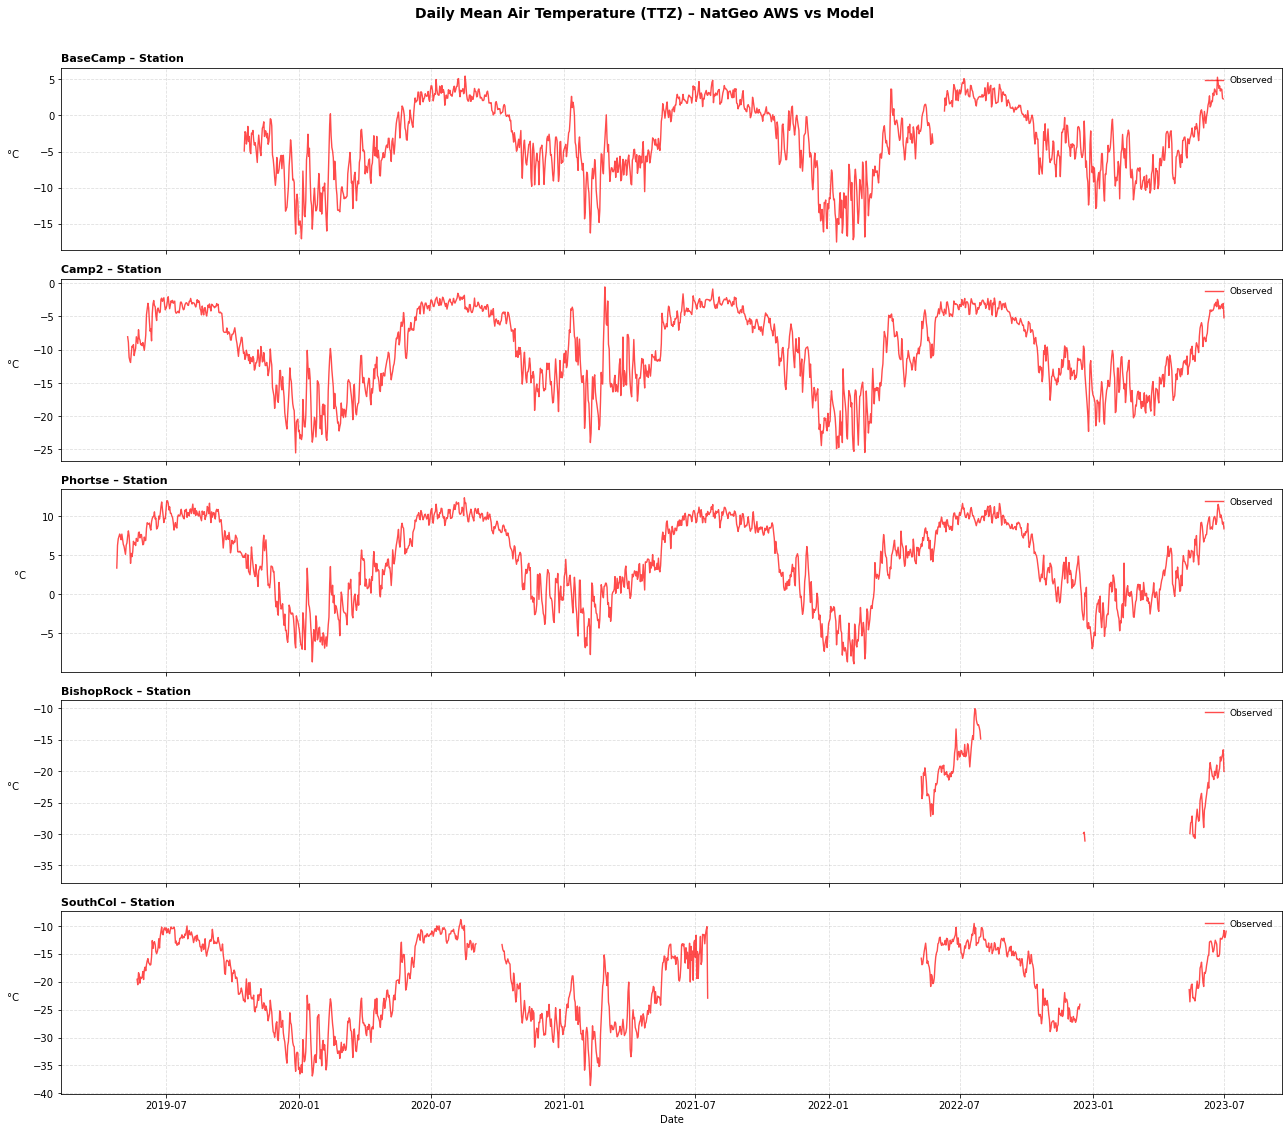

In [13]:

# --- Create subplots (one per station) ---
fig, axes = plt.subplots(len(stations_tt_daily_natgeo), 1, figsize=(18, 16), sharex=True)

# --- Plot each station ---
for ax, (name, obs_series) in zip(axes, stations_tt_daily_natgeo.items()):
    # Observed daily temperature (line)
    ax.plot(obs_series.index, obs_series.values, color='red', lw=1.4, alpha=0.7, label="Observed")

      # Style + Title
    ax.set_ylabel("°C", rotation=0, labelpad=20)
    ax.set_title(f"{name} – Station",
                 loc='left', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(frameon=False, loc='upper right', fontsize=9)

# Shared labels and figure title
axes[-1].set_xlabel("Date")
fig.suptitle("Daily Mean Air Temperature (TTZ) – NatGeo AWS vs Model",
             fontsize=14, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.97])

plotname = f"support_FIGSX_timeseries_daily_tas.natgeo"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")

plt.show()


In [15]:
date_ranges = {
    "BaseCamp": f"{idate_bc} to {fdate_bc}",
    "Camp2": f"{idate_c2} to {fdate_c2}",
    "Phortse": f"{idate_phort} to {fdate_phort}",
    "BishopRock": f"{idate_bish} to {fdate_bish}",
    "SouthCol": f"{idate_sc} to {fdate_sc}"
}

In [18]:
import pandas as pd
import numpy as np

# =========================================================
# Function: seasonal mean ± std
# =========================================================

def seasonal_stats(series):

    seasons = {
        "DJFM": [12, 1, 2, 3],
        "AM": [4, 5],
        "JJAS": [6, 7, 8, 9],
        "ON": [10, 11]
    }

    stats = {}

    for season, months in seasons.items():

        data = series[series.index.month.isin(months)]

        mean = data.mean()
        std = data.std()

        stats[season] = f"{mean:.2f} ± {std:.2f}"

    return stats

# =========================================================
# Dates dictionary
# =========================================================


# =========================================================
# Build table
# =========================================================

rows = []

for station in stations_tt_daily_natgeo.keys():

    # Observation series
    obs = stations_tt_daily_natgeo[station]#.to_pandas()

    # Seasonal climatology
    clim_obs = seasonal_stats(obs)

    # Add row
    rows.append({

        "Station": station,

        "DJFM": clim_obs["DJFM"],

        "AM": clim_obs["AM"],

        "JJAS": clim_obs["JJAS"],

        "ON": clim_obs["ON"],
         "Period": date_ranges[station],
    })

# =========================================================
# Create DataFrame
# =========================================================

df_clim = pd.DataFrame(rows)

print(df_clim)

# =========================================================
# Save CSV
# =========================================================

outfile = f"{resultsDir}/seasonal_climatology_TTZ_natgeo.csv"

df_clim.to_csv(outfile, index=False)

print(f"\nSaved: {outfile}")

      Station           DJFM             AM           JJAS             ON  \
0    BaseCamp   -7.99 ± 3.92   -3.65 ± 2.73    2.41 ± 1.24   -3.21 ± 2.66   
1       Camp2  -16.07 ± 4.44  -11.10 ± 3.24   -4.00 ± 1.49  -10.57 ± 3.29   
2     Phortse   -1.47 ± 3.20    4.76 ± 2.34    9.68 ± 1.11    3.91 ± 2.84   
3  BishopRock  -31.79 ± 3.17  -25.13 ± 3.10  -18.63 ± 3.52      nan ± nan   
4    SouthCol  -28.73 ± 4.08  -21.93 ± 4.73  -13.47 ± 2.34  -23.20 ± 3.90   

                     Period  
0  2019-10-17 to 2023-06-30  
1  2019-05-09 to 2023-07-01  
2  2019-04-24 to 2023-07-01  
3  2022-05-09 to 2023-07-01  
4  2019-05-22 to 2023-07-04  

Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/compu_results//seasonal_climatology_TTZ_natgeo.csv
